In [ ]:
!unzip /content/sample_data/data.zip

เอาต์พุตของการสตรีมมีการตัดเหลือเพียง 5000 บรรทัดสุดท้าย
  inflating: data/train/open eyes/s0036_05431_1_1_1_0_0_01.png  
  inflating: data/train/open eyes/s0036_05432_1_1_1_0_0_01.png  
  inflating: data/train/open eyes/s0036_05433_1_1_1_0_0_01.png  
  inflating: data/train/open eyes/s0036_05434_1_1_1_0_0_01.png  
  inflating: data/train/open eyes/s0036_05435_1_1_1_0_0_01.png  
  inflating: data/train/open eyes/s0036_05436_1_1_1_0_0_01.png  
  inflating: data/train/open eyes/s0036_05437_1_1_1_0_0_01.png  
  inflating: data/train/open eyes/s0036_05438_1_1_1_0_0_01.png  
  inflating: data/train/open eyes/s0036_05439_1_1_1_0_0_01.png  
  inflating: data/train/open eyes/s0036_05440_1_1_1_0_0_01.png  
  inflating: data/train/open eyes/s0036_05441_1_1_1_0_0_01.png  
  inflating: data/train/open eyes/s0036_05442_1_1_1_0_0_01.png  
  inflating: data/train/open eyes/s0036_05443_1_1_1_0_0_01.png  
  inflating: data/train/open eyes/s0036_05444_1_1_1_0_0_01.png  
  inflating: data/train/open eyes

In [70]:
import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, Input, GlobalAveragePooling2D
from tensorflow.keras import regularizers
from keras.callbacks import ModelCheckpoint, EarlyStopping
from keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [ ]:
trainData = '/content/data/train'
testData = '/content/data/test'

# Iterate through each folder in the root directory
folder_image_count = {}

for data in os.listdir(trainData):
    path_folder = os.path.join(trainData, data)
    if os.path.isdir(path_folder):
        # Count the number of image files in the folder
        num_images = len([name for name in os.listdir(path_folder) if os.path.isfile(os.path.join(path_folder, name)) and name.lower().endswith(('.png', '.jpg', '.jpeg'))])
        folder_image_count[data] = num_images

# Extract folder names and corresponding image counts
folders = list(folder_image_count.keys())
img_counts = list(folder_image_count.values())

for folder, count in folder_image_count.items():
    print(f"{folder}: {count} images")

.ipynb_checkpoints: 0 images
Closed: 40380 images
Opened: 41295 images


In [ ]:
categories = ['Opened', 'Closed']
image_size = (150, 150)

X = []
Y = []

for label, category in enumerate(categories):
    folder_path = os.path.join(trainData, category)
    for filename in os.listdir(folder_path):
        if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
            img_path = os.path.join(folder_path, filename)
            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, image_size)
            X.append(img)
            Y.append(label)

X = np.array(X)
Y = np.array(Y)

print(len(X))
print(len(Y))

81675
81675


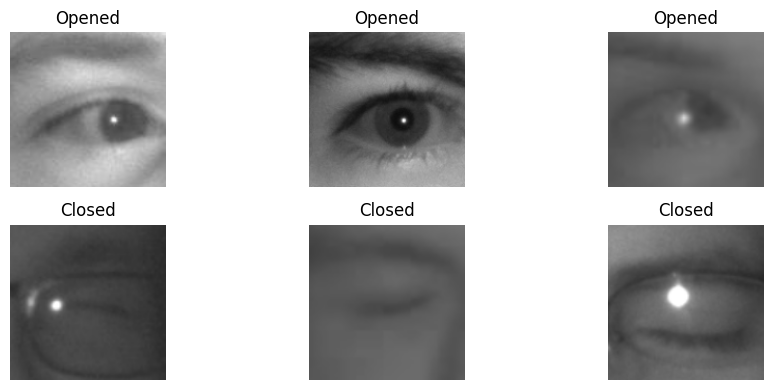

In [ ]:
idx_open = np.random.choice(np.where(Y == 0)[0], 3, replace=False)
idx_close = np.random.choice(np.where(Y == 1)[0], 3, replace=False)

Top3pics = np.concatenate([idx_open, idx_close])
plt.figure(figsize=(10, 4))

for i, idx in enumerate(Top3pics):
    plt.subplot(2, 3, i + 1)
    plt.imshow(X[idx])
    plt.title('Opened' if Y[idx] == 0 else 'Closed')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
x_train, x_validation, y_train, y_validation = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=60
)

print(x_train.shape)
print(y_train.shape)
print(x_validation.shape)
print(y_validation.shape)

(65340, 150, 150, 3)
(65340,)
(16335, 150, 150, 3)
(16335,)


In [ ]:
num_classes = 2
y_train = to_categorical(y_train, num_classes)
y_validation = to_categorical(y_validation, num_classes)

In [ ]:
Effmodel = tf.keras.applications.EfficientNetV2B3(include_top=False, weights='imagenet')
Effmodel.summary()

Model: "efficientnetv2-b3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, None,      │          0 │ -                 │
│ (InputLayer)        │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_3         │ (None, None,      │          0 │ input_layer_4[0]… │
│ (Rescaling)         │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_3     │ (None, None,      │          0 │ rescaling_3[0][0] │
│ (Normalization)     │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, None,      │      1,080 │ normalization_3[… │
│                     │ None, 40)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, None,      │        160 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ None, 40)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, None,      │          0 │ stem_bn[0][0]     │
│ (Activation)        │ None, 40)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, None,      │      5,760 │ stem_activation[… │
│ (Conv2D)            │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_bn  │ (None, None,      │         64 │ block1a_project_… │
│ (BatchNormalizatio… │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_ac… │ (None, None,      │          0 │ block1a_project_… │
│ (Activation)        │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_project_co… │ (None, None,      │      2,304 │ block1a_project_… │
│ (Conv2D)            │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_project_bn  │ (None, None,      │         64 │ block1b_project_… │
│ (BatchNormalizatio… │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_project_ac… │ (None, None,      │          0 │ block1b_project_… │
│ (Activation)        │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_drop        │ (None, None,      │          0 │ block1b_project_… │
│ (Dropout)           │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_add (Add)   │ (None, None,      │          0 │ block1b_drop[0][… │
│                     │ None, 16)         │            │ block1a_project_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_conv │ (None, None,      │      9,216 │ block1b_add[0][0] │
│ (Conv2D)            │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_bn   │ (None, None,      │        256 │ block2a_expand_c… │
│ (BatchNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_act… │ (None, None,      │          0 │ block2a_expand_b

 Total params: 12,930,622 (49.33 MB)

 Trainable params: 12,821,406 (48.91 MB)

 Non-trainable params: 109,216 (426.62 KB)

In [ ]:
model = tf.keras.applications.EfficientNetV2B3(
    include_top=False,
    weights='imagenet',
    input_tensor=None,
    input_shape = (150, 150, 3),
    classes=2,
)

for layer in model.layers:
    layer.trainable = False

for block in range(3, 7):
    block_layers = [layer for layer in model.layers if f'block{block}' in layer.name]
    num_trainable = max(1, int(len(block_layers) * 0.3))

    for layer in block_layers[-num_trainable:]:
        layer.trainable = True

In [ ]:
inputs = Input(shape=(150, 150, 3))

x = model(inputs)
x = GlobalAveragePooling2D()(x)
x = Dense(
    1024,
    activation='relu',
    kernel_regularizer=regularizers.l2(0.01)
)(x)
x = Dropout(0.2)(x)
outputs = Dense(num_classes, activation='softmax')(x)

FinalModel = Model(inputs, outputs)

FinalModel.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

bestModel = ModelCheckpoint(
    'best.keras', monitor='val_accuracy', verbose=1, save_best_only=True
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

batch_size = 64
history = FinalModel.fit(
    x_train,
    y_train,
    batch_size=batch_size,
    epochs=20,
    validation_data=(x_validation, y_validation),
    callbacks=[bestModel, early_stopping],
    verbose=1
)

Epoch 1/20
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.9809 - loss: 1.2961
Epoch 1: val_accuracy improved from None to 0.99002, saving model to best.keras

Epoch 1: finished saving model to best.keras
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 265s 196ms/step - accuracy: 0.9869 - loss: 0.3372 - val_accuracy: 0.9900 - val_loss: 0.0340
Epoch 2/20
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.9901 - loss: 0.0367
Epoch 2: val_accuracy improved from 0.99002 to 0.99033, saving model to best.keras

Epoch 2: finished saving model to best.keras
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 140s 137ms/step - accuracy: 0.9897 - loss: 0.0386 - val_accuracy: 0.9903 - val_loss: 0.0349
Epoch 3/20
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.9914 - loss: 0.0313
Epoch 3: val_accuracy improved from 0.99033 to 0.99198, saving model to best.keras

Epoch 3: finished saving model to best.keras
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 142s 139ms/step - accuracy: 0.9915 - loss: 0.0314 - val_accuracy: 0.9

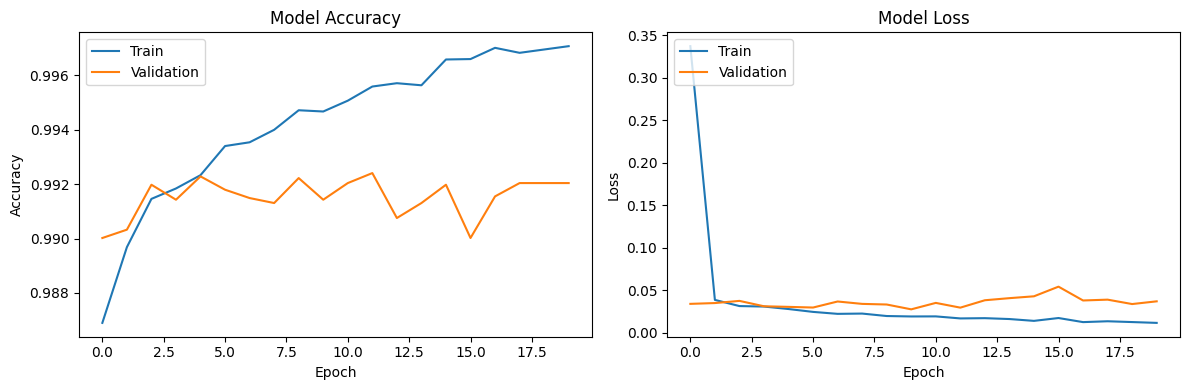

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

#acc
ax1.plot(history.history['accuracy'])
ax1.plot(history.history['val_accuracy'])
ax1.set_title('Model Accuracy')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(['Train', 'Validation'], loc='upper left')

#loss
ax2.plot(history.history['loss'])
ax2.plot(history.history['val_loss'])
ax2.set_title('Model Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend(['Train', 'Validation'], loc='upper left')

plt.tight_layout()
plt.show()

511/511 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      8426
           1       1.00      0.99      0.99      7909

    accuracy                           0.99     16335
   macro avg       0.99      0.99      0.99     16335
weighted avg       0.99      0.99      0.99     16335



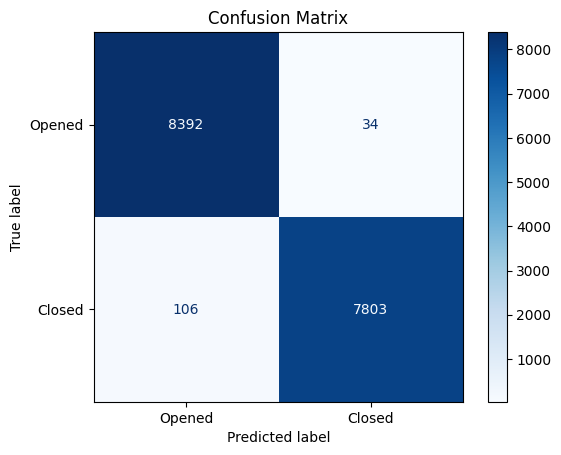

In [76]:
y_pred = FinalModel.predict(x_validation)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_validation, axis=1)

print(classification_report(y_true, y_pred_classes))

cm = confusion_matrix(y_true, y_pred_classes)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Opened', 'Closed']
)
disp.plot(cmap='Blues')

plt.title("Confusion Matrix")
plt.show()

In [77]:
FinalModel.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b3 (Functional)  │ (None, 5, 5, 1536)     │    12,930,622 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1536)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1024)           │     1,573,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2)              │         2,050 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,168,022 (96.01 MB)

 Trainable params: 5,330,730 (20.34 MB)

 Non-trainable params: 9,175,830 (35.00 MB)

 Optimizer params: 10,661,462 (40.67 MB)

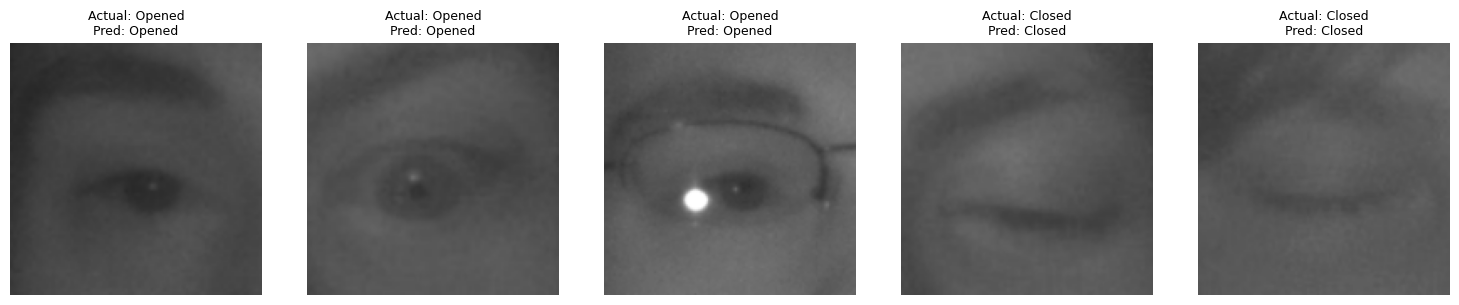

In [ ]:
model_predict = tf.keras.models.load_model('best.keras')

categories = ['Opened', 'Closed']

X_samples = []
Y_samples = []

for category in categories:
    folder_path = os.path.join(testData, category)
    image_files = os.listdir(folder_path)[:3]
    for image_file in image_files:
        image_path = os.path.join(folder_path, image_file)
        img = Image.open(image_path).convert('RGB')
        img = img.resize((150, 150))
        img_array = np.array(img)
        X_samples.append(img_array)
        Y_samples.append(0 if category == 'Opened' else 1)
        if len(X_samples) == 5:
            break
    if len(X_samples) == 5:
        break

plt.figure(figsize=(15, 3))
for i in range(5):
    image = X_samples[i]

    prediction = model_predict.predict(
        np.expand_dims(image, axis=0),
        verbose=0
    )

    predicted_label = np.argmax(prediction)
    actual_class = categories[Y_samples[i]]
    predicted_class = categories[predicted_label]
    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title(
        f"Actual: {actual_class}\nPred: {predicted_class}",
        fontsize=9
    )
    plt.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
archi = tf.keras.models.load_model('best.keras')
archi.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b3 (Functional)  │ (None, 5, 5, 1536)     │    12,930,622 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1536)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1024)           │     1,573,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2)              │         2,050 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,168,022 (96.01 MB)

 Trainable params: 5,330,730 (20.34 MB)

 Non-trainable params: 9,175,830 (35.00 MB)

 Optimizer params: 10,661,462 (40.67 MB)

In [ ]:
from google.colab import files
files.download('best.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>